# Isochrones

This notebook builds isochrones on an intermodal `UrbanGraph` from IduEdu (walk + public transport):

- `get_graph_isochrones` with `geometry_type="radius"` and `"ways"` for one origin;
- `get_stepped_graph_isochrones` with bands of width `step` for `"radius"`, `"ways"` and `"separate"`;
- an animation of stepped isochrones.

The method is described on the [isochrones page](../isochrones.rst). The interactive maps show a light copy of every
result (`for_map`: outlines simplified by 2 m), which keeps the notebook small.

The last section, *Your own area*, shows what to replace to get the same pictures for another territory.

In [1]:
# Install required packages (uncomment if needed)
# !pip install objectnat iduedu

In [2]:
import geopandas as gpd
from iduedu import config, download_osm_pbf, get_4326_boundary, get_intermodal_graph
from shapely import Point

from objectnat import get_graph_isochrones, get_stepped_graph_isochrones

In [3]:
def for_map(gdf, tolerance=2.0):
    """A light copy for a web map: outlines simplified by `tolerance` metres, coordinates rounded to about 10 cm."""
    local = gdf.to_crs(gdf.estimate_utm_crs())
    local["geometry"] = local.simplify(tolerance)
    light = local.to_crs(4326)
    light["geometry"] = light.geometry.set_precision(1e-6)
    return light[~light.is_empty]

## 1. Intermodal graph

The graph covers the district and is clipped to its boundary. Edge weights are `time_min` (minutes) and
`length_meter` (metres).

In [4]:
# Vasilyevsky Island district, Saint Petersburg (OSM relation 1114252).
# IduEdu >= 2.4 cuts the territory out of the Geofabrik extract (pip install "iduedu[pbf]");
# without download_osm_pbf, the calls below without the `with` block query the Overpass API.
pbf = download_osm_pbf(osm_id=1114252, region="northwestern-fed-district")
with config.use_pbf(pbf):
    poly = get_4326_boundary(osm_id=1114252)
    G_intermodal = get_intermodal_graph(territory=poly, clip_by_territory=True)

2026-11-06 15:51:06.202 | WARNING  | iduedu.graph.transformers:keep_largest_connected_component:64 - Removing 338 nodes outside the largest strongly connected component. Retaining 21181 of 21519 nodes.


2026-11-06 15:51:06.224 | WARNING  | iduedu.graph_builders.intermodal_builders:join_pt_walk_graph:248 - Public transport nodes dropped with the smaller components: {'trolleybus': 2}


## 2. Origin

One origin point in WGS 84; it is snapped to the nearest graph node.

In [5]:
# Define a single point of interest
point = gpd.GeoDataFrame(geometry=[Point(30.27060176, 59.93546846)], crs=4326)

## 3. Radius isochrone

Union of buffers around the nodes reachable within 10 minutes, each with the residual budget converted to a
distance with the median edge speed of the graph.

In [6]:
isochrones_radius = get_graph_isochrones(
    G_intermodal,
    geometry_type='radius',
    gdf_origins=point,
    weight_type="time_min",
    weight_value_cutoff=10,
)

# Visualize
for_map(isochrones_radius).explore(tiles="OpenStreetMap")

## 4. Ways isochrone

Pedestrian edges reachable within 10 minutes, buffered by `road_buffer_size` (5 m by default).

In [7]:
isochrones_ways = get_graph_isochrones(
    G_intermodal,
    geometry_type='ways',
    gdf_origins=point,
    weight_type="time_min",
    weight_value_cutoff=10,
)

# Visualize
for_map(isochrones_ways).explore(tiles="OpenStreetMap")

## 5. Comparison

The radius isochrone (blue) also covers places between streets; the ways isochrone (red) follows the streets.

In [8]:
m = for_map(isochrones_radius).explore(tiles="OpenStreetMap", color='blue', name='Radius')
for_map(isochrones_ways).explore(m=m, color='red', name='Ways')

## 6. Stepped isochrones, radius

Bands of 3 minutes up to 15 minutes; `dist` is the upper bound of the band.

In [9]:
stepped_radius = get_stepped_graph_isochrones(
    G_intermodal,
    geometry_type='radius',
    gdf_origins=point,
    weight_type="time_min",
    weight_value_cutoff=15,
    step=3,
)

for_map(stepped_radius).explore(tiles="OpenStreetMap", column='dist')

## 7. Stepped isochrones, ways

Voronoi cells of the reachable nodes clipped to the buffered streets, in bands of 3 minutes.

In [10]:
stepped_ways = get_stepped_graph_isochrones(
    G_intermodal,
    geometry_type='ways',
    gdf_origins=point,
    weight_type="time_min",
    weight_value_cutoff=15,
    step=3,
)
for_map(stepped_ways).explore(tiles="OpenStreetMap", column='dist')

## 8. Stepped isochrones, separate

Independent buffers per band of 2 minutes up to 10 minutes.

In [11]:
stepped_separate = get_stepped_graph_isochrones(
    G_intermodal,
    geometry_type='separate',
    gdf_origins=point,
    weight_type="time_min",
    weight_value_cutoff=10,
    step=2,
)

for_map(stepped_separate).explore(tiles="OpenStreetMap", column='dist')

### Parameters used

- `geometry_type`: `"radius"`, `"ways"` or `"separate"` (stepped isochrones also accept `None`, Voronoi cells);
- `weight_type`: `"time_min"` (minutes) or `"length_meter"` (metres);
- `weight_value_cutoff`: the budget, in the units of `weight_type`;
- `step`: band width for stepped isochrones;
- `buffer_factor` (`"separate"`) and `road_buffer_size` (`"ways"`, metres).

## 9. Animation of stepped isochrones

In [12]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from shapely import Point
import geopandas as gpd
from objectnat import get_stepped_graph_isochrones

edges = G_intermodal.edges_gdf.copy()
point = gpd.GeoDataFrame(geometry=[Point(30.27060176, 59.93546846)], crs=4326).to_crs(edges.crs)
bbox = gpd.GeoDataFrame(geometry=[poly], crs=4326).to_crs(edges.crs)

type_colors = {
    'walk': '#a3a3a3',
    'bus': '#1f77b4',
    'trolleybus': '#2ca02c',
    'tram': '#ff7f0e',
    'subway': '#9467bd',
    'boarding': '#8c564b'
}

edges['color'] = edges['type'].map(type_colors).fillna('#d9d9d9')  # other edge types in light grey

steps = [0.1, 0.5, 1, 2, 3, 4, 5]

fig, ax = plt.subplots(figsize=(9, 7), dpi=90)
plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)

edges_plot = edges.plot(ax=ax, color=edges['color'], alpha=0.5, linewidth=0.1, legend=True)
bbox.boundary.plot(ax=ax, color='black', linestyle='--', linewidth=1)
point.plot(ax=ax, color='red', markersize=50)
ax.set_axis_off()


def update(step):
    for coll in ax.collections:
        if coll.get_label() == 'isochrone':
            coll.remove()

    result = get_stepped_graph_isochrones(
        G_intermodal,
        geometry_type='separate',
        gdf_origins=point,
        weight_type="time_min",
        weight_value_cutoff=15,
        step=step,
    )
    result.plot(ax=ax, alpha=1, label='isochrone', column='dist', legend=False)
    ax.set_title(f'Isochrone with step = {step} minutes')


ani = FuncAnimation(
    fig,
    update,
    frames=steps,
    repeat=True,
    interval=2000
)

ani.save('isochrone_animation.gif', writer='pillow', fps=1)  # written next to the notebook
plt.close(fig)

The saved animation, a frame per step:

![Stepped isochrones with steps of 0.1–5 minutes](https://raw.githubusercontent.com/IDUclub/ObjectNat/assets/isochrones_steps_animation.gif)

## 10. Your own area

The territory is an OSM relation (the `relation` of a district or a city on openstreetmap.org); `REGION` names
the Geofabrik extract to cut it from (`iduedu.find_geofabrik_region` finds it for a polygon; without it IduEdu
asks Overpass once to choose the extract). The result is a GeoDataFrame: draw it with matplotlib (here over the
streets of the graph, with the territory boundary), explore it on a web map or save it for GIS with `to_file`.

2026-11-06 15:51:26.239 | WARNING  | iduedu.graph.transformers:keep_largest_connected_component:64 - Removing 338 nodes outside the largest strongly connected component. Retaining 21181 of 21519 nodes.


2026-11-06 15:51:26.262 | WARNING  | iduedu.graph_builders.intermodal_builders:join_pt_walk_graph:248 - Public transport nodes dropped with the smaller components: {'trolleybus': 2}


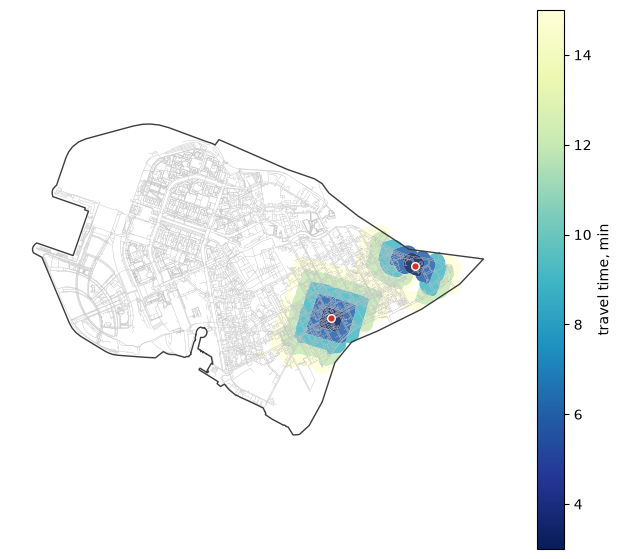

In [13]:
import matplotlib.pyplot as plt

OSM_ID, REGION = 1114252, "northwestern-fed-district"  # your territory
my_origins = gpd.GeoDataFrame(geometry=[Point(30.2706, 59.9355), Point(30.2959, 59.9441)], crs=4326)  # your points

with config.use_pbf(download_osm_pbf(osm_id=OSM_ID, region=REGION)):  # downloaded once, then cached
    my_boundary = get_4326_boundary(osm_id=OSM_ID)
    my_graph = get_intermodal_graph(territory=my_boundary, clip_by_territory=True)
my_bands = get_stepped_graph_isochrones(
    my_graph, gdf_origins=my_origins, weight_type="time_min", weight_value_cutoff=15, step=3,
    geometry_type="separate",
)

local = my_bands.to_crs(my_graph.nodes_gdf.crs)
streets = my_graph.edges_gdf[my_graph.edges_gdf["type"] == "walk"]  # the street network as the background
ax = streets.plot(color="#c2c2c2", linewidth=0.3, figsize=(8, 7))
local.plot(ax=ax, column="dist", cmap="YlGnBu_r", alpha=0.85, legend=True, legend_kwds={"label": "travel time, min"})
gpd.GeoSeries([my_boundary], crs=4326).to_crs(local.crs).boundary.plot(ax=ax, color="#3d3d3d", linewidth=1)
my_origins.to_crs(local.crs).plot(ax=ax, color="#d7301f", markersize=30, edgecolor="white", zorder=5)
ax.set_axis_off()
plt.show()
# my_bands.to_file("my_isochrones.gpkg")  # for GIS

In [14]:
for_map(my_bands).explore(column="dist", cmap="YlGnBu_r", tiles="OpenStreetMap")